Having extracted the T/S profiles at the Denmark Strait location (67.5°N, 334.0°E) in Extract_profile_clean.ipynb and then saving the profile locations, I've decided to rerun the plotting code for the T-S diagram, now only for values of sigma_theta > 27.8 (or the densest layer, if that one doesn't exist), to be closer to Eldevik et al.(2009).  

In [2]:
import pickle

# Load the save|d late profile data
with open('/Users/jaimepalter/Library/CloudStorage/OneDrive-UniversityofRhodeIsland/New Ideas/AMOC Lunch Bunch/profiles_late_period_DenStr.pkl', 'rb') as f:
    profiles_late = pickle.load(f)

print("✓ Denmark Strait 1995-2014 profiles loaded from 'profiles_late_period.pkl'")

✓ Denmark Strait 1995-2014 profiles loaded from 'profiles_late_period.pkl'


In [4]:
# Load the saved mid-profile data
with open('/Users/jaimepalter/Library/CloudStorage/OneDrive-UniversityofRhodeIsland/New Ideas/AMOC Lunch Bunch/profiles_mid_period_DenStr.pkl', 'rb') as f:
    profiles_mid = pickle.load(f)

print("✓ Denmark Strait 1950-1969 profiles loaded from 'profiles_mid_period.pkl'")

✓ Denmark Strait 1950-1969 profiles loaded from 'profiles_mid_period.pkl'


In [6]:
#Bring in results of Price and Barringer model for Denmark Strait 
import scipy.io as sio
import matplotlib.pyplot as plt
import numpy as np

# Load data
#data = sio.loadmat('FBC_transportSiCTi.mat'); #path:  '/Users/jaimepalter/Library/CloudStorage/OneDrive-UniversityofRhodeIsland/New Ideas/AMOC Lunch Bunch'
mat_data = sio.loadmat('/Users/jaimepalter/Library/CloudStorage/OneDrive-UniversityofRhodeIsland/New Ideas/AMOC Lunch Bunch/transport_data.mat')
Si = mat_data['Si']
CTi = mat_data['CTi']
Transport = mat_data['T']


Long plotting script next!

Number of labels created: 25
CAS-ESM2-0: 'thetao'

1. GFDL-ESM4 EARLY:
   mask_early.sum() = 2
   type(mask_early) = <class 'numpy.ndarray'>
   temp_mean_early = 2.1429524421691895
   sal_mean_early = 35.05553436279297
   Within xlim? True
   Within ylim? True
   LATE: mask_late.sum() = 2

2. EC-Earth3-AerChem EARLY:
   mask_early.sum() = 1
   type(mask_early) = <class 'numpy.ndarray'>
   temp_mean_early = 2.3950533866882324
   sal_mean_early = 35.011985778808594
   Within xlim? True
   Within ylim? True
   LATE: mask_late.sum() = 2

3. CanESM5 EARLY:
   mask_early.sum() = 0
   type(mask_early) = <class 'numpy.ndarray'>
   temp_mean_early = nan
   sal_mean_early = nan
   Within xlim? False
   Within ylim? False
  ⚠️  SKIPPED CanESM5: NaN mean values (empty mask)

3. CMCC-ESM2 EARLY:
   mask_early.sum() = 2
   type(mask_early) = <class 'numpy.ndarray'>
   temp_mean_early = 0.6134686470031738
   sal_mean_early = 34.92616653442383
   Within xlim? True
   Within ylim? True
   LATE: mask_la

/var/folders/h1/j3p_b5ts7314ws9g_tynb4g80000gn/T/ipykernel_15748/3097743595.py:79: RuntimeWarning: Mean of empty slice
  temp_mean_early = np.nanmean(temp_early[mask_early])
/var/folders/h1/j3p_b5ts7314ws9g_tynb4g80000gn/T/ipykernel_15748/3097743595.py:80: RuntimeWarning: Mean of empty slice
  sal_mean_early = np.nanmean(sal_early[mask_early])
/var/folders/h1/j3p_b5ts7314ws9g_tynb4g80000gn/T/ipykernel_15748/3097743595.py:115: RuntimeWarning: Mean of empty slice
  sal_mean_late = np.nanmean(sal_late[mask_late])
/var/folders/h1/j3p_b5ts7314ws9g_tynb4g80000gn/T/ipykernel_15748/3097743595.py:114: RuntimeWarning: Mean of empty slice
  temp_mean_late = np.nanmean(temp_late[mask_late])


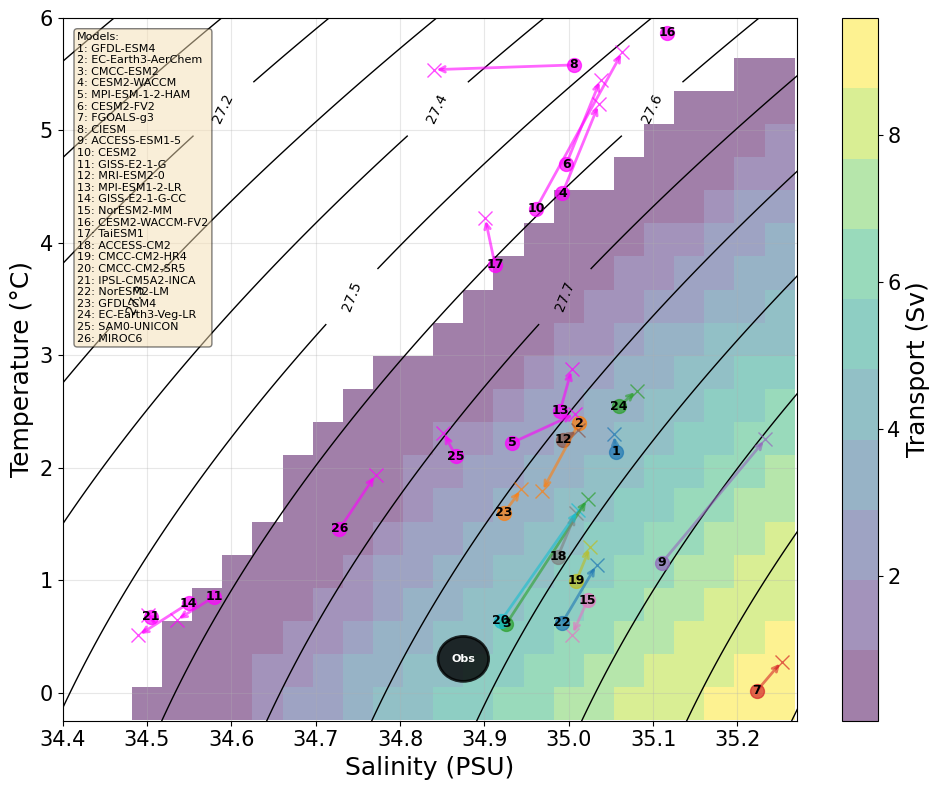

In [9]:
import gsw

location = 'DenStrait'

fig, ax = plt.subplots(figsize=(10, 8))

# Create grid
sal_range = np.linspace(33, 35.5, 100)  # Match your xlim
temp_range = np.linspace(-2, 6, 100)    # Match your ylim
Sal, Temp = np.meshgrid(sal_range, temp_range)

# === ADD Transport CONTOURS FIRST (behind everything) ===
Transmean = np.squeeze(Transport[:, :, :200].mean(axis=2))
cmap_discrete = plt.cm.get_cmap('viridis', 10)
pcm = ax.pcolormesh(Si, CTi, Transmean/1e6, 
                    cmap=cmap_discrete,
                    alpha=0.5,
                    shading='auto',
                    zorder=0)

# Add colorbar for transport
cbar = plt.colorbar(pcm, ax=ax, label='Transport (Sv)')
cbar.set_label('Transport (Sv)', fontsize=18)
cbar.ax.tick_params(labelsize=15)

# Calculate density
pressure = 350
density = gsw.sigma0(Sal, Temp) 

# Plot contours (on top, zorder=2)
contours = ax.contour(Sal, Temp, density, 
                      levels=np.arange(26, 28.5, 0.1),
                      colors='black', linewidths=1,
                      zorder=2)

# Try labeling WITHOUT inline
labels = ax.clabel(contours, fontsize=10, fmt='%0.1f')
print(f"Number of labels created: {len(labels)}")

# Store model info
model_list = []  # Track model names and numbers

# Plot early and late data with arrows
model_counter = 1
for model_name in profiles_mid.keys():
    
    # ===== CHECK BOTH EARLY AND LATE HAVE DATA AT THIS LOCATION =====
    if location not in profiles_mid[model_name]:
        continue
    if location not in profiles_late[model_name]:
        print(f"  ⚠️  SKIPPED {model_name}: no late period data at {location}")
        continue
    # ===================================================================
    
    try:
        # === EARLY PERIOD ===
        data_early = profiles_mid[model_name][location]
        depth_early = data_early['depth']
        temp_early = np.squeeze(data_early['thetao'])
        sal_early = np.squeeze(data_early['so'])
        CMIPdensity_early = gsw.sigma0(sal_early, temp_early)
        
        valid_TS_early = (~np.isnan(temp_early) & ~np.isnan(sal_early))
        overflow_density_mask_early = ((CMIPdensity_early > 27.8) & valid_TS_early)
        
        if overflow_density_mask_early.sum() > 0:
            mask_early = overflow_density_mask_early
            use_density_filter_early = True
        else:
            mask_early = (depth_early > 350) & (depth_early <= 700) & (~np.isnan(temp_early))
            use_density_filter_early = False
        
        # ===== DIAGNOSTIC: Check mask_early =====
        print(f"\n{model_counter}. {model_name} EARLY:")
        print(f"   mask_early.sum() = {mask_early.sum()}")
        print(f"   type(mask_early) = {type(mask_early)}")
        # ========================================
        
        temp_mean_early = np.nanmean(temp_early[mask_early])
        sal_mean_early = np.nanmean(sal_early[mask_early])
        # ===== NEW DIAGNOSTIC =====
        print(f"   temp_mean_early = {temp_mean_early}")
        print(f"   sal_mean_early = {sal_mean_early}")
        print(f"   Within xlim? {34.4 <= sal_mean_early <= 35.27}")
        print(f"   Within ylim? {-0.25 <= temp_mean_early <= 6}")
        # ==========================
        # ===== NEW: Check if mask is empty =====
        if np.isnan(temp_mean_early) or np.isnan(sal_mean_early):
            print(f"  ⚠️  SKIPPED {model_name}: NaN mean values (empty mask)")
            continue
        # ========================================
        
        # === LATE PERIOD ===
        data_late = profiles_late[model_name][location]
        depth_late = data_late['depth']
        temp_late = np.squeeze(data_late['thetao'])
        sal_late = np.squeeze(data_late['so'])
        CMIPdensity_late = gsw.sigma0(sal_late, temp_late)
        
        valid_TS_late = (~np.isnan(temp_late) & ~np.isnan(sal_late))
        overflow_density_mask_late = ((CMIPdensity_late > 27.8) & valid_TS_late)
        
        if overflow_density_mask_late.sum() > 0:
            mask_late = overflow_density_mask_late
            use_density_filter_late = True
        else:
            mask_late = (depth_late > 350) & (depth_late <= 700) & (~np.isnan(temp_late))
            use_density_filter_late = False
        
        # ===== DIAGNOSTIC: Check mask_late =====
        print(f"   LATE: mask_late.sum() = {mask_late.sum()}")
        # ========================================
        
        temp_mean_late = np.nanmean(temp_late[mask_late])
        sal_mean_late = np.nanmean(sal_late[mask_late])
        
        # ===== NEW: Check if mask is empty =====
        if np.isnan(temp_mean_late) or np.isnan(sal_mean_late):
            print(f"  ⚠️  SKIPPED {model_name}: NaN mean values (empty mask)")
            continue
        # ========================================
        
        # ===== PLOT EARLY DOT =====
        if use_density_filter_early:
            line = ax.plot(sal_mean_early, temp_mean_early, 'o', 
                          linewidth=1.5, alpha=0.7, markersize=10, zorder=3)
            color = line[0].get_color()
        else:
            ax.plot(sal_mean_early, temp_mean_early, 'o', color='magenta',
                   linewidth=1.5, alpha=0.7, markersize=10, zorder=3)
            color = 'magenta'
        # ==========================
        
        # Add number inside circle
        ax.text(sal_mean_early, temp_mean_early, str(model_counter), 
               ha='center', va='center', fontsize=9, fontweight='bold', 
               color='black', zorder=4)
        
        # ===== PLOT LATE X AND ARROW =====
        ax.plot(sal_mean_late, temp_mean_late, 'x', color=color, 
               linewidth=3, alpha=0.7, markersize=10, zorder=3)
        
        ax.annotate('', 
                   xy=(sal_mean_late, temp_mean_late),           
                   xytext=(sal_mean_early, temp_mean_early),     
                   arrowprops=dict(arrowstyle='->', 
                                  lw=2, 
                                  alpha=0.6,
                                  color=color),
                   zorder=3)
        # ==================================
        
        # Store info for legend creation
        model_list.append((model_counter, model_name))
        model_counter += 1
        
    except Exception as e:
        print(f"{model_name}: {e}")

# Add observation region
from matplotlib.patches import Ellipse

ellipse = Ellipse((34.875, 0.3),
                  width=0.06,
                  height=0.4,
                  facecolor='black', 
                  alpha=0.8,
                  edgecolor='black',
                  linewidth=2,
                  zorder=3)
ax.add_patch(ellipse)
ax.text(34.875, 0.3, 'Obs', ha='center', va='center', 
       fontsize=8, fontweight='bold', color='white', zorder=4)

ax.set_xlabel('Salinity (PSU)', fontsize=18)
ax.set_ylim(-0.25, 6)
ax.set_xlim(34.4, 35.27)
ax.set_ylabel('Temperature (°C)', fontsize=18)
#ax.set_title(f'T-S Diagram - {location}', fontsize=14)
ax.tick_params(axis='both', labelsize=15)
ax.grid(True, alpha=0.3, zorder=0)

# Create a text-based legend showing model numbers
legend_text = "Models:\n" + "\n".join([f"{num}: {name}" for num, name in model_list])
ax.text(0.02, 0.98, legend_text, transform=ax.transAxes, 
       fontsize=8, verticalalignment='top',
       bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.show()